In [1]:
import json
import pickle
from datetime import datetime
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
from clases_po import HFDatasetLoader

SEMILLA = 42
PALETA = ["#1f6fe5", "#10a179", "#f2661b", "#8a3ff0", "#e5384b", "#f5b300", "#151b6e", "#7a8199", "#2ec4b6", "#ff7aa2"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)

d:\IUDigital\2026\q4\machine learning\repositorios\ML_2026Q4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Etapa 1 · Extracción  → escena 2
Todas las ventas de una tienda online del Reino Unido (artículos de regalo, muchos clientes mayoristas),
de diciembre de 2009 a diciembre de 2011. UCI Online Retail II, publicado en Hugging Face.

In [2]:
loader = HFDatasetLoader(dataset_name="mishrasiddhant911/online-retail-II", split="train",
                         filename="datos/online_retail_II.csv")
df_retail_crudo = loader.load()   # 1 · cargar

# Algunas copias del dataset usan otros nombres de columna: los unificamos
df_retail_crudo = df_retail_crudo.rename(columns={"InvoiceNo": "Invoice", "UnitPrice": "Price", "CustomerID": "Customer ID"})
print("Forma (filas, columnas):", df_retail_crudo.shape)
df_retail_crudo.head()

Forma (filas, columnas): (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
diccionario = pd.DataFrame([
    ("Invoice", "número de factura; si empieza con C es una cancelación"),
    ("StockCode", "código del producto"),
    ("Description", "nombre del producto"),
    ("Quantity", "unidades (negativas en devoluciones)"),
    ("InvoiceDate", "fecha y hora de la factura"),
    ("Price", "precio unitario en libras esterlinas"),
    ("Customer ID", "identificador del cliente"),
    ("Country", "país del cliente"),
], columns=["columna", "significado"])
diccionario

,columna,significado
0,Invoice,número de factura; si empieza con C es una can...
1,StockCode,código del producto
2,Description,nombre del producto
3,Quantity,unidades (negativas en devoluciones)
4,InvoiceDate,fecha y hora de la factura
5,Price,precio unitario en libras esterlinas
6,Customer ID,identificador del cliente
7,Country,país del cliente


In [4]:
df = df_retail_crudo.copy()
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df.info()
print("\nDesde", df["InvoiceDate"].min(), "hasta", df["InvoiceDate"].max())
print("Facturas distintas:", df["Invoice"].nunique(), "· clientes distintos:", df["Customer ID"].nunique(),
      "· países:", df["Country"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Desde 2009-12-01 07:45:00 hasta 2011-12-09 12:50:00
Facturas distintas: 53628 · clientes distintos: 5942 · países: 43


In [5]:
lineas_por_cliente = df.groupby("Customer ID").size()
print(lineas_por_cliente.describe().round(1))

count     5942.0
mean       138.7
std        359.7
min          1.0
25%         21.0
50%         53.0
75%        144.0
max      13097.0
dtype: float64


## Etapa 2 · Preprocesamiento  → escena 3
### 2.1 Validar antes de confiar
Cada validación produce una **métrica** y una **decisión**. Para los problemas que se excluyen,
reportamos también cuánto dinero representan.

In [6]:
df["Importe"] = df["Quantity"] * df["Price"]
n = len(df)
ventas_brutas = df.loc[df["Importe"] > 0, "Importe"].sum()

sin_cliente = df["Customer ID"].isna()
cancelacion = df["Invoice"].str.startswith("C")
precio_invalido = df["Price"] <= 0
cantidad_negativa_sin_c = (df["Quantity"] <= 0) & ~cancelacion
duplicado = df.duplicated()
# Códigos que no son productos: envíos, comisiones, ajustes, muestras (POST, DOT, M, BANK CHARGES, AMAZONFEE...)
no_producto = ~df["StockCode"].str.match(r"^\d{5}")

def fila(validacion, mascara, decision):
    dinero = df.loc[mascara & (df["Importe"] > 0), "Importe"].sum()
    return (validacion, int(mascara.sum()), round(mascara.mean() * 100, 2), round(dinero / ventas_brutas * 100, 2), decision)

calidad = pd.DataFrame([
    fila("Clientes sin identificar (Customer ID nulo)", sin_cliente, "excluir y reportar"),
    fila("Devoluciones (factura con C)", cancelacion, "separar: tasa de devolución por cliente"),
    fila("Cantidad ≤ 0 sin ser cancelación", cantidad_negativa_sin_c, "excluir: ajustes de inventario"),
    fila("Precio ≤ 0", precio_invalido, "excluir: no son ventas"),
    fila("Códigos que no son productos", no_producto, "excluir: envíos, comisiones, ajustes"),
    fila("Filas duplicadas", duplicado, "eliminar"),
], columns=["validación", "filas", "% filas", "% del dinero", "decisión"])
calidad

,validación,filas,% filas,% del dinero,decisión
0,Clientes sin identificar (Customer ID nulo),243007,22.77,15.40,excluir y reportar
1,Devoluciones (factura con C),19494,1.83,0.00,separar: tasa de devolución por cliente
2,Cantidad ≤ 0 sin ser cancelación,3457,0.32,0.00,excluir: ajustes de inventario
3,Precio ≤ 0,6207,0.58,0.00,excluir: no son ventas
4,Códigos que no son productos,6093,0.57,4.12,"excluir: envíos, comisiones, ajustes"
5,Filas duplicadas,34335,3.22,2.37,eliminar


In [7]:
# Valores extremos: ¿error o mayorista?
print("Cantidad: percentiles 50, 99 y 99,9:", df["Quantity"].quantile([.5, .99, .999]).round(0).tolist())
df.loc[df["Quantity"].abs() >= 10_000, ["Invoice", "Description", "Quantity", "Price", "Customer ID", "InvoiceDate"]]

Cantidad: percentiles 50, 99 y 99,9: [3.0, 100.0, 500.0]


,Invoice,Description,Quantity,Price,Customer ID,InvoiceDate
90857,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0,2010-02-15 11:57:00
127166,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0,2010-03-17 13:09:00
127167,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902.0,2010-03-17 13:09:00
127168,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0,2010-03-17 13:09:00
127169,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902.0,2010-03-17 13:09:00
135027,502269,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940.0,2010-03-23 15:36:00
135028,502269,PACK OF 12 SUKI TISSUES,10000,0.25,17940.0,2010-03-23 15:36:00
135029,502269,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940.0,2010-03-23 15:36:00
135030,502269,PACK OF 12 WOODLAND TISSUES,10000,0.25,17940.0,2010-03-23 15:36:00
192197,507637,FLAG OF ST GEORGE CAR FLAG,10200,0.00,NaN,2010-05-10 14:55:00


In [8]:
registro = [("datos crudos", len(df))]
df = df.loc[~duplicado].copy();                    registro.append(("sin duplicados", len(df)))
df = df.loc[df["Customer ID"].notna()].copy();     registro.append(("con cliente identificado", len(df)))
df["Customer ID"] = df["Customer ID"].astype(int)
devoluciones = df.loc[df["Invoice"].str.startswith("C")].copy()
compras = df.loc[~df["Invoice"].str.startswith("C")].copy()
registro.append(("compras (sin cancelaciones)", len(compras)))
compras = compras.loc[(compras["Quantity"] > 0) & (compras["Price"] > 0)];   registro.append(("cantidad y precio > 0", len(compras)))
compras = compras.loc[compras["StockCode"].str.match(r"^\d{5}")];             registro.append(("solo productos", len(compras)))
pd.DataFrame(registro, columns=["paso", "filas"])

,paso,filas
0,datos crudos,1067371
1,sin duplicados,1033036
2,con cliente identificado,797885
3,compras (sin cancelaciones),779495
4,cantidad y precio > 0,779425
5,solo productos,776577


### 2.3 Construir el perfil: RFM
- **Recencia (R)** = días entre la última compra y la fecha de corte
- **Frecuencia (F)** = número de facturas distintas
- **Monto (M)** = Σ cantidad × precio

**🔹 Variables del bloque**
| Variable | Qué es | Para qué |
|---|---|---|
| `FECHA_CORTE` | día siguiente a la última compra (2011-12-10) | punto de referencia de la recencia; así la recencia mínima es 0 |
| `construir_rfm(transacciones, fecha_corte)` | función reutilizable | crear el RFM para cualquier fecha; el monitoreo la vuelve a usar |
| `rfm` | DataFrame **una fila por cliente** | la tabla que se clusteriza |
| `rfm["Recencia"]` | días desde la última compra | **menor es mejor** |
| `rfm["Frecuencia"]` | número de facturas distintas | mayor = compra más veces |
| `rfm["Monto"]` | Σ Importe | mayor = gasta más |
| `devuelto` | valor devuelto por cliente | numerador de la tasa |
| `rfm["TasaDevolucion"]` | devuelto ÷ monto comprado, máximo 1 | queda fuera del modelo base: es el reto |

In [9]:
FECHA_CORTE = compras["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

def construir_rfm(transacciones, fecha_corte):
    return transacciones.groupby("Customer ID").agg(
        Recencia=("InvoiceDate", lambda s: (fecha_corte - s.max()).days),
        Frecuencia=("Invoice", "nunique"),
        Monto=("Importe", "sum"))

rfm = construir_rfm(compras, FECHA_CORTE)

# Tasa de devolución por cliente: no entra al modelo base, es el reto de la clase
devuelto = devoluciones.groupby("Customer ID")["Importe"].sum().abs()
rfm["TasaDevolucion"] = (devuelto.reindex(rfm.index).fillna(0) / rfm["Monto"]).clip(upper=1)

print("Fecha de corte:", FECHA_CORTE.date(), "· clientes con perfil:", len(rfm))
rfm.head()

C:\Users\USUARIO\AppData\Local\Temp\ipykernel_39028\1648706332.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  FECHA_CORTE = compras["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)


Fecha de corte: 2011-12-10 · clientes con perfil: 5852


,Recencia,Frecuencia,Monto,TasaDevolucion
Customer ID,,,,
12346,325,3,77352.96,1.000000
12347,2,8,4921.53,0.000000
12348,75,5,1658.40,0.000000
12349,18,3,3678.69,0.006565
12350,310,1,294.40,0.000000


### 2.4 Describir: ¿la media representa al cliente típico?

**🔹 Variables del bloque**
| Variable | Qué es | Para qué |
|---|---|---|
| `desc` | estadísticas de R, F y M | comparar media, mediana y dispersión |
| `skew` | asimetría | 0 = simétrica; mayor que 1 = cola larga a la derecha |
| `media ÷ mediana` | razón | cuánto se aleja el promedio del cliente típico |

In [10]:
desc = rfm[["Recencia", "Frecuencia", "Monto"]].agg(["mean", "median", "std", "min", "max", "skew"]).T
desc["media ÷ mediana"] = desc["mean"] / desc["median"]
desc.round(2)

,mean,median,std,min,max,skew,media ÷ mediana
Recencia,199.73,95.00,208.52,0.00,738.00,0.89,2.10
Frecuencia,6.25,3.00,12.75,1.00,373.00,12.04,2.08
Monto,2916.71,856.02,14306.85,2.95,580987.04,25.33,3.41


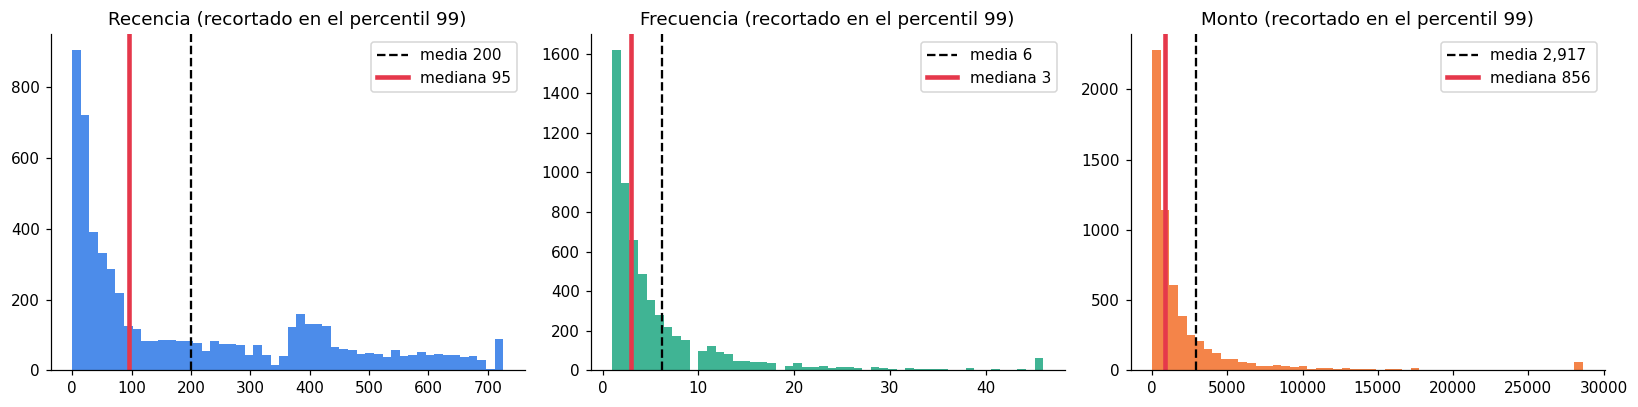

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
for eje, col, color in zip(ejes, ["Recencia", "Frecuencia", "Monto"], PALETA):
    x = rfm[col].clip(upper=rfm[col].quantile(.99))
    eje.hist(x, bins=50, color=color, alpha=.8)
    eje.axvline(rfm[col].mean(), color="black", ls="--", label=f"media {rfm[col].mean():,.0f}")
    eje.axvline(rfm[col].median(), color=PALETA[4], lw=3, label=f"mediana {rfm[col].median():,.0f}")
    eje.set_title(f"{col} (recortado en el percentil 99)")
    eje.legend()
plt.tight_layout()
plt.show()

In [12]:
# Concentración: ¿qué parte del dinero aportan los mejores clientes?
orden = rfm["Monto"].sort_values(ascending=False)
top20 = orden.head(int(len(orden) * .2)).sum() / orden.sum()
print(f"El 20 % de los clientes con mayor monto aporta el {top20:.1%} de los ingresos")
print(compras.groupby("Country")["Importe"].sum().sort_values(ascending=False).head(5).div(compras["Importe"].sum()).round(3))

El 20 % de los clientes con mayor monto aporta el 77.2% de los ingresos
Country
United Kingdom    0.837
EIRE              0.034
Netherlands       0.032
Germany           0.022
France            0.018
Name: Importe, dtype: float64


## Etapa 3 · Entrenamiento  → escena 4
### 3.1 K-Means mide distancias: la escala importa
Distancia euclidiana: d(x, y) = √Σ (xⱼ − yⱼ)². Sin transformar, el monto se come la distancia.

Dos pasos: **logaritmo** (`log1p`) para los extremos y **estandarización** z = (x − μ) ÷ σ para igualar pesos.

**🔹 Variables del bloque**
| Variable | Qué es | Para qué |
|---|---|---|
| `VARIABLES` | `["Recencia", "Frecuencia", "Monto"]` | columnas que entran al modelo |
| `X_crudo` | matriz NumPy de n × 3 | los valores sin transformar |
| `X_log` | `log1p(X_crudo)` = ln(1 + x) | comprimir los extremos; el +1 evita el error de ln(0) cuando la recencia es 0 |
| `escalador` | `StandardScaler` ajustado | guarda la μ y la σ de cada columna; se reutiliza para clientes nuevos |
| `X` | matriz final estandarizada | media 0 y desviación 1 en cada variable: **lo que ve K-Means** |


In [14]:
VARIABLES = ["Recencia", "Frecuencia", "Monto"]
X_crudo = rfm[VARIABLES].to_numpy(dtype=float)
X_log = np.log1p(X_crudo)
escalador = StandardScaler().fit(X_log)
X = escalador.transform(X_log)

pd.DataFrame({"rango sin transformar": X_crudo.max(0) - X_crudo.min(0),
              "rango con log": X_log.max(0) - X_log.min(0),
              "media escalada": X.mean(0), "desviación escalada": X.std(0)}, index=VARIABLES).round(2)

,rango sin transformar,rango con log,media escalada,desviación escalada
Recencia,738.00,6.61,-0.0,1.0
Frecuencia,372.00,5.23,0.0,1.0
Monto,580984.09,11.90,-0.0,1.0


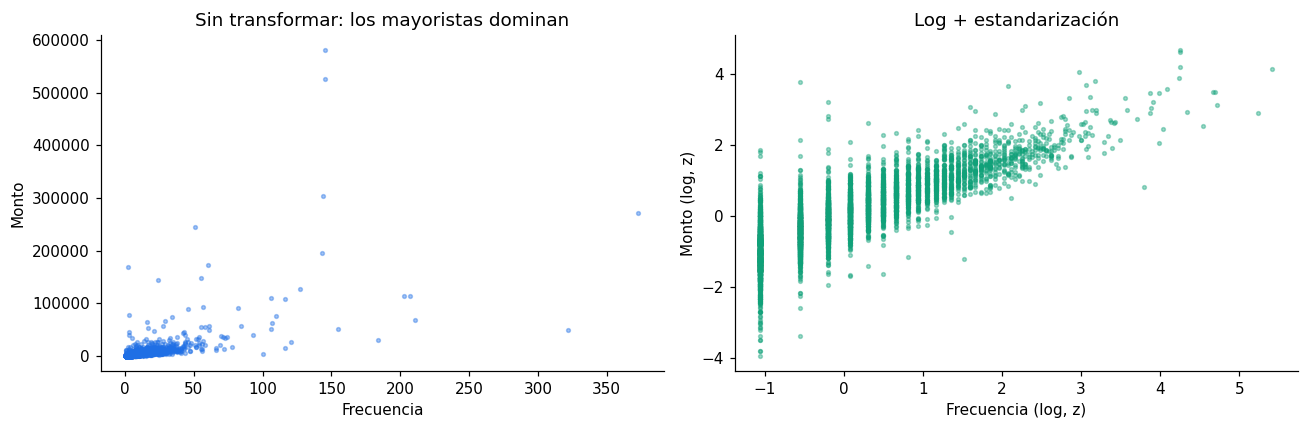

In [15]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].scatter(X_crudo[:, 1], X_crudo[:, 2], s=6, alpha=.4, color=PALETA[0])
ejes[0].set_xlabel("Frecuencia"); ejes[0].set_ylabel("Monto"); ejes[0].set_title("Sin transformar: los mayoristas dominan")
ejes[1].scatter(X[:, 1], X[:, 2], s=6, alpha=.4, color=PALETA[1])
ejes[1].set_xlabel("Frecuencia (log, z)"); ejes[1].set_ylabel("Monto (log, z)"); ejes[1].set_title("Log + estandarización")
plt.tight_layout()
plt.show()

### 3.2 K-Means para varios k
Minimiza la **inercia** = Σₖ Σ ‖x − μₖ‖². `n_init=10` prueba 10 inicios y se queda con el mejor;
`random_state` hace el resultado repetible. No hay partición de prueba: no hay y contra la cual comparar.

**🔹 Variables del bloque**
| Variable | Qué es | Para qué |
|---|---|---|
| `modelos` | diccionario k → modelo `KMeans` entrenado | reutilizar cada modelo sin reentrenar |
| `km.labels_` | segmento asignado a cada cliente (0 … k − 1) | calcular métricas y perfiles |
| `km.inertia_` | inercia del modelo | método del codo |
| `km.cluster_centers_` | coordenadas de los centroides (en z) | describir y nombrar segmentos |
| `n_clusters`, `n_init=10`, `random_state` | hiperparámetros | k grupos · 10 inicios distintos (se queda con el de menor inercia) · reproducibilidad |
| `metricas_k` | tabla de métricas por k | elegir k |
| `grupo más pequeño` | tamaño del segmento menor | ¿se puede gestionar una campaña con ese grupo? |

In [16]:
filas = []
modelos = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    modelos[k] = km
    filas.append({"k": k, "inercia": km.inertia_,
                  "silueta": silhouette_score(X, km.labels_),
                  "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
                  "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
                  "grupo más pequeño": np.bincount(km.labels_).min()})
metricas_k = pd.DataFrame(filas).set_index("k")
metricas_k.round(3)

,inercia,silueta,Davies-Bouldin,Calinski-Harabasz,grupo más pequeño
k,,,,,
2,8572.745,0.438,0.874,6130.156,2314
3,6358.499,0.347,1.035,5150.159,1183
4,4948.335,0.365,0.940,4966.647,1110
5,4128.217,0.342,0.955,4754.675,447
6,3578.145,0.336,0.960,4567.475,443
7,3204.687,0.304,0.978,4362.678,334
8,2915.615,0.296,0.985,4192.141,344
9,2673.992,0.291,1.005,4064.924,256
10,2483.498,0.289,1.003,3939.562,228


## Etapa 4 · Análisis y métricas  → escena 5
### 4.1 ¿Cuántos grupos existen de verdad?
- **Inercia (codo):** buscamos donde deja de bajar mucho.
- **Silueta:** s = (b − a) ÷ máx(a, b) → cerca de 1 bien agrupado, 0 frontera, negativa grupo equivocado.
- **Davies-Bouldin:** más bajo es mejor. **Calinski-Harabasz:** más alto es mejor.

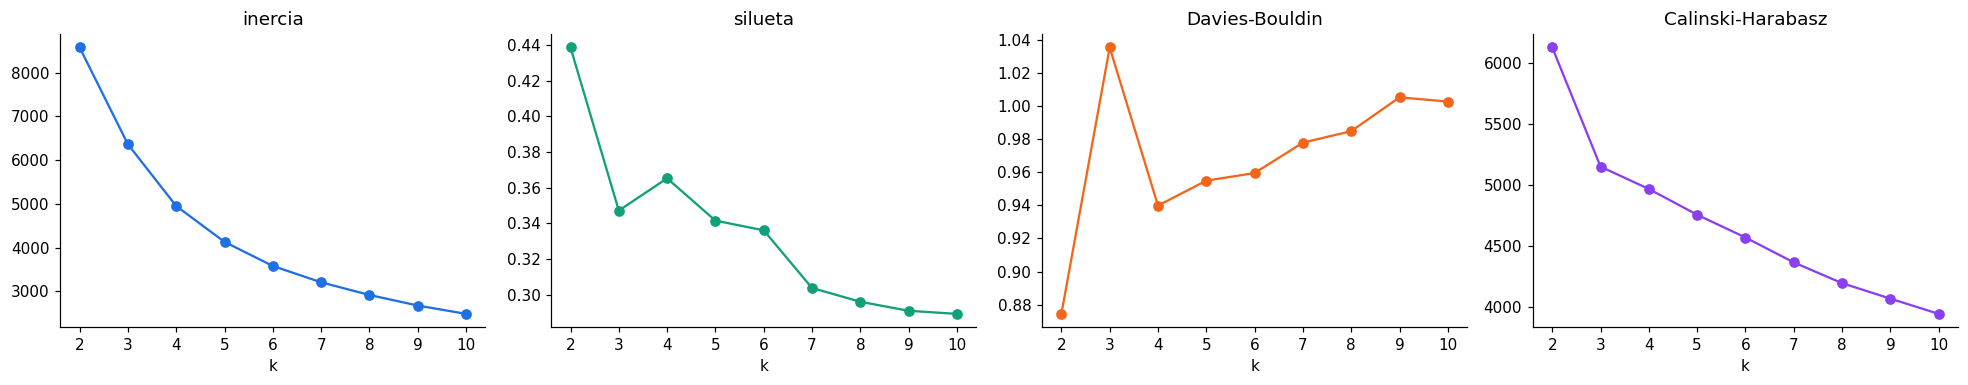

In [17]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 3.6))
for eje, col, color in zip(ejes, ["inercia", "silueta", "Davies-Bouldin", "Calinski-Harabasz"], PALETA):
    eje.plot(metricas_k.index, metricas_k[col], "o-", color=color)
    eje.set_title(col); eje.set_xlabel("k")
plt.tight_layout()
plt.show()

**🔹 Variables del bloque**
| Variable | Qué es | Para qué |
|---|---|---|
| `K_ELEGIDO` | el k decidido: métricas + negocio | parámetro central; cámbialo en el reto |
| `modelo` | el `KMeans` con k = 4 | el modelo final |
| `rfm["segmento"]` | número de segmento por cliente | ⚠️ el número (0, 1, 2, 3) **no tiene significado**: el orden es arbitrario; el nombre sale del perfil |

In [18]:
# Elige k mirando las cuatro métricas Y el negocio (¿puedes nombrar y gestionar cada grupo?)
K_ELEGIDO = 4
modelo = modelos[K_ELEGIDO]
rfm["segmento"] = modelo.labels_
print(f"k = {K_ELEGIDO} · silueta {metricas_k.loc[K_ELEGIDO, 'silueta']:.3f}")

k = 4 · silueta 0.365


### 4.2 Escenarios

In [20]:
sin_escalar = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA).fit(X_crudo)
def resumen(nombre, etiquetas, espacio):
    tam = np.bincount(etiquetas)
    return {"escenario": nombre, "grupos": len(tam), "silueta": silhouette_score(espacio, etiquetas),
            "grupo más grande %": tam.max() / tam.sum() * 100, "grupo más pequeño": tam.min()}
escenarios = pd.DataFrame([
    resumen("1 · k = 2", modelos[2].labels_, X),
    resumen("2 · k = 10", modelos[10].labels_, X),
    resumen(f"3 · k elegido = {K_ELEGIDO}", modelo.labels_, X),
    resumen(f"4 · k = {K_ELEGIDO} sin log ni escalado", sin_escalar.labels_, X_crudo),
]).set_index("escenario")
escenarios.round(3)


,grupos,silueta,grupo más grande %,grupo más pequeño
escenario,,,,
1 · k = 2,2,0.438,60.458,2314
2 · k = 10,10,0.289,18.353,228
3 · k elegido = 4,4,0.365,35.099,1110
4 · k = 4 sin log ni escalado,4,0.940,98.975,2


**🔹 Variables del bloque**
| Variable | Qué es | Para qué |
|---|---|---|
| `perfil` | tabla por segmento con **medianas** de R, F y M | describir cada grupo; la mediana resiste a los extremos |
| `% clientes`, `% ingresos` | peso de cada segmento | cuánto representa en personas y en dinero |
| `centroides` | DataFrame con los centroides en z | la huella del segmento: > 0 está por encima del promedio, < 0 por debajo |
| `nombrar(c)` | regla de nombres | reciente si la recencia en z es < 0,3; valor = promedio de frecuencia y monto en z |
| `nombres`, `rfm["nombre"]` | nombre de cada segmento y de cada cliente | traducir números a lenguaje de negocio |

In [21]:
perfil = rfm.groupby("segmento").agg(
    clientes=("Monto", "size"), Recencia_mediana=("Recencia", "median"),
    Frecuencia_mediana=("Frecuencia", "median"), Monto_mediano=("Monto", "median"), Monto_total=("Monto", "sum"))
perfil["% clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["% ingresos"] = perfil["Monto_total"] / perfil["Monto_total"].sum() * 100

# Nombres a partir de los centroides (en unidades estandarizadas): recencia baja = compró hace poco
centroides = pd.DataFrame(modelo.cluster_centers_, columns=VARIABLES)
# Regla: "reciente" si su recencia no está claramente por encima del promedio (z < 0,3);
# "valor" = promedio de frecuencia y monto en z. Ajusta los umbrales si tu perfil lo pide.
def nombrar(c):
    reciente, valor = c["Recencia"] < 0.3, (c["Frecuencia"] + c["Monto"]) / 2
    if reciente and valor > 0.8: return "Campeones"
    if reciente and valor > 0:   return "Leales"
    if reciente:                 return "Nuevos o recientes"
    if valor > 0:                return "En riesgo"
    return "Perdidos"
nombres = centroides.apply(nombrar, axis=1)
nombres = nombres.where(~nombres.duplicated(keep=False), nombres + " " + nombres.index.astype(str))
perfil["nombre"] = nombres
rfm["nombre"] = rfm["segmento"].map(nombres)
perfil.sort_values("% ingresos", ascending=False).round(1)

,clientes,Recencia_mediana,Frecuencia_mediana,Monto_mediano,Monto_total,% clientes,% ingresos,nombre
segmento,,,,,,,,
1,1110,15.0,13.0,5117.7,12217497.4,19.0,71.6,Campeones
3,1468,157.0,5.0,1580.4,3150628.2,25.1,18.5,En riesgo
0,1220,23.0,3.0,707.7,1002636.2,20.8,5.9,Nuevos o recientes
2,2054,398.0,1.0,291.4,697806.2,35.1,4.1,Perdidos


**📊 Lectura de resultados**
| Segmento | Clientes | Recencia mediana | Facturas | Monto mediano | % ingresos |
|---|---|---|---|---|---|
| **Campeones** | 1 110 (19,0 %) | 15 días | 13 | 5 118 | **71,6 %** |
| **En riesgo** | 1 468 (25,1 %) | 157 días | 5 | 1 580 | 18,5 % |
| **Nuevos o recientes** | 1 220 (20,8 %) | 23 días | 3 | 708 | 5,9 % |
| **Perdidos** | 2 054 (35,1 %) | 398 días | 1 | 291 | 4,1 % |

- **1 de cada 5 clientes genera 7 de cada 10 libras**: los campeones son el negocio.
- **En riesgo** es el dinero recuperable: compraban bien (5 facturas, 1 580 libras), pero hace cinco meses que no vuelven.
- **Perdidos** son el 35 % de los clientes y apenas el 4 % de los ingresos: compraron una sola vez hace más de un año.
- Cada grupo se puede nombrar y tiene una acción distinta: **los grupos sirven al negocio**.

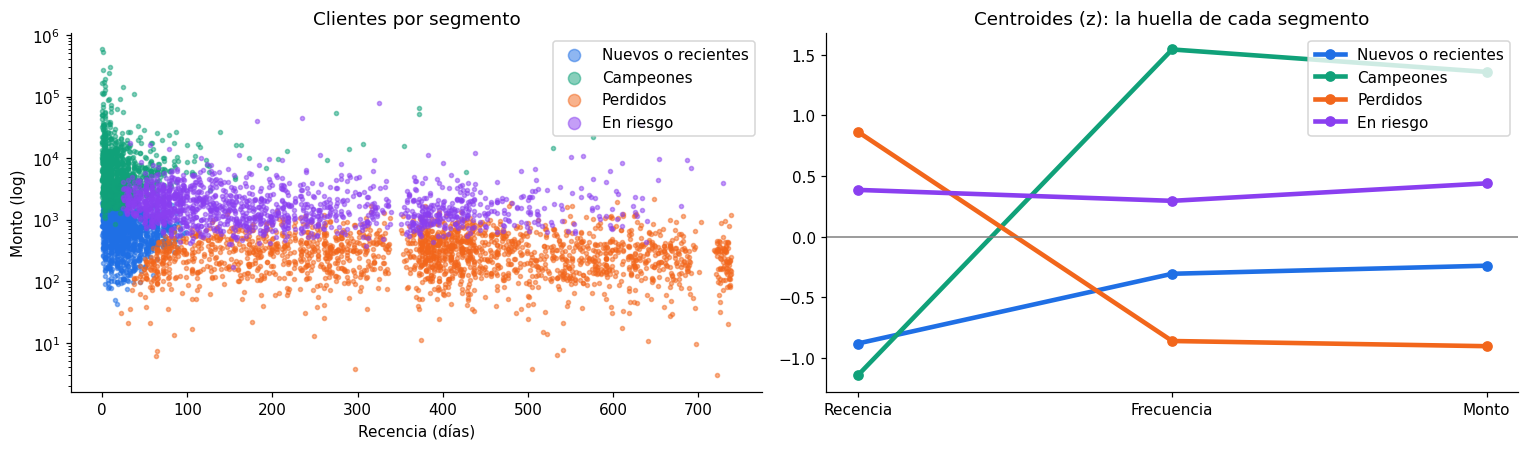

: 

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2))
for s, g in rfm.groupby("segmento"):
    ejes[0].scatter(g["Recencia"], g["Monto"], s=7, alpha=.5, color=PALETA[s], label=nombres[s])
ejes[0].set_yscale("log"); ejes[0].set_xlabel("Recencia (días)"); ejes[0].set_ylabel("Monto (log)")
ejes[0].set_title("Clientes por segmento"); ejes[0].legend(markerscale=3)
for s in centroides.index:
    ejes[1].plot(VARIABLES, centroides.loc[s], "o-", lw=3, color=PALETA[s], label=nombres[s])
ejes[1].axhline(0, color="gray", lw=1)
ejes[1].set_title("Centroides (z): la huella de cada segmento"); ejes[1].legend()
plt.tight_layout()
plt.show()